# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [1]:
SURNAME_NAME = 'Савков Олександр'
GROUP        = 'ШІ-33'
NUMBER       = 6

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Савков Олександр | ШІ-33 | номер 6


In [2]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 6   ·   Савков Олександр   ·   ШІ-33

   Ринок:  Cherkasy
   Товар:  молоко   (у наборі даних: Milk - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | |
| **Підпис** | |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [3]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.signal import argrelextrema
from statsmodels.tsa.seasonal import STL, seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
warnings.filterwarnings('ignore')

df = pd.read_csv('ціни_україна_2014_2017.csv')
df['date'] = pd.to_datetime(dict(year=df['рік'], month=df['місяць'], day=1))
grid = pd.date_range('2014-03-01', '2017-12-01', freq='MS')
raw = df[(df['ринок'] == MARKET) & (df['товар'] == GOOD)].set_index('date')['ціна'].reindex(grid)

print('місяців у сітці:', len(raw), '| з виміром:', raw.notna().sum(), '| пропуск:', raw[raw.isna()].index.strftime('%m.%Y').tolist())
print('записів за 08.2017 у всьому наборі:', (df['date'] == '2017-08-01').sum())

місяців у сітці: 46 | з виміром: 45 | пропуск: ['08.2017']
записів за 08.2017 у всьому наборі: 0


**Висновок до завдання 1:**

У сітці з березня 2014 по грудень 2017 46 місяців, вимір є у 45, пропущений лише серпень 2017, і в моєму ряді цей пропуск один. Виник він не через обробку, а в самому джерелі: у всьому файлі немає жодного запису за 08.2017 ні по одному ринку й товару, тобто цей місяць просто не потрапив у вивантаження World Food Programme. Якби я не привів ряд до повної сітки через `reindex`, пропуску не було б видно взагалі — у ряді було б 45 рядків, а `isna()` показав би нуль.

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [4]:
gap = raw[raw.isna()].index[0]
ways = pd.Series({
    'перенесення останнього': raw.ffill()[gap],
    'лінійна інтерполяція': raw.interpolate('linear')[gap],
    'кубічна інтерполяція': raw.reset_index(drop=True).interpolate('cubic')[raw.index.get_loc(gap)],
})
print(ways.round(4))
s = raw.interpolate('linear')

df.groupby('ринок')['date'].agg(['min', 'max', 'nunique']).sort_values('nunique').head(4)

перенесення останнього    16.9167
лінійна інтерполяція      16.8717
кубічна інтерполяція      16.6664
dtype: float64


,min,max,nunique
ринок,,,
Crimea,2014-03-01,2014-03-01,1
m. Sevastopol,2014-03-01,2014-04-01,2
Luhanska,2014-03-01,2017-12-01,40
Donetska,2014-03-01,2017-12-01,42


**Висновок до завдання 2:**

Перенесення останнього значення дає 16.9167, лінійна інтерполяція 16.8717, кубічна 16.6664, і я обрав лінійну. Липень 16.9167, а вересень лише трохи нижчий, 16.8267, тому лінійна ставить середнє між сусідами й нічого не вигадує, перенесення ігнорує вересень, а кубічна опускає серпень нижче за обох сусідів і домальовує коливання, якого в даних немає; розбіжність між способами 0.25 грн, близько 1.5 % рівня, тож на висновки вибір не впливає.

Заповнювати пропуск було б неприпустимо, якби він був структурним, а не випадковим. У цьому ж наборі Crimea має лише один місяць даних (03.2014), m. Sevastopol два, Luhanska 40 і Donetska 42 — там збір цін припинився, і заповнення означало б вигадати ціни для ринку, на якому їх ніхто не вимірював.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

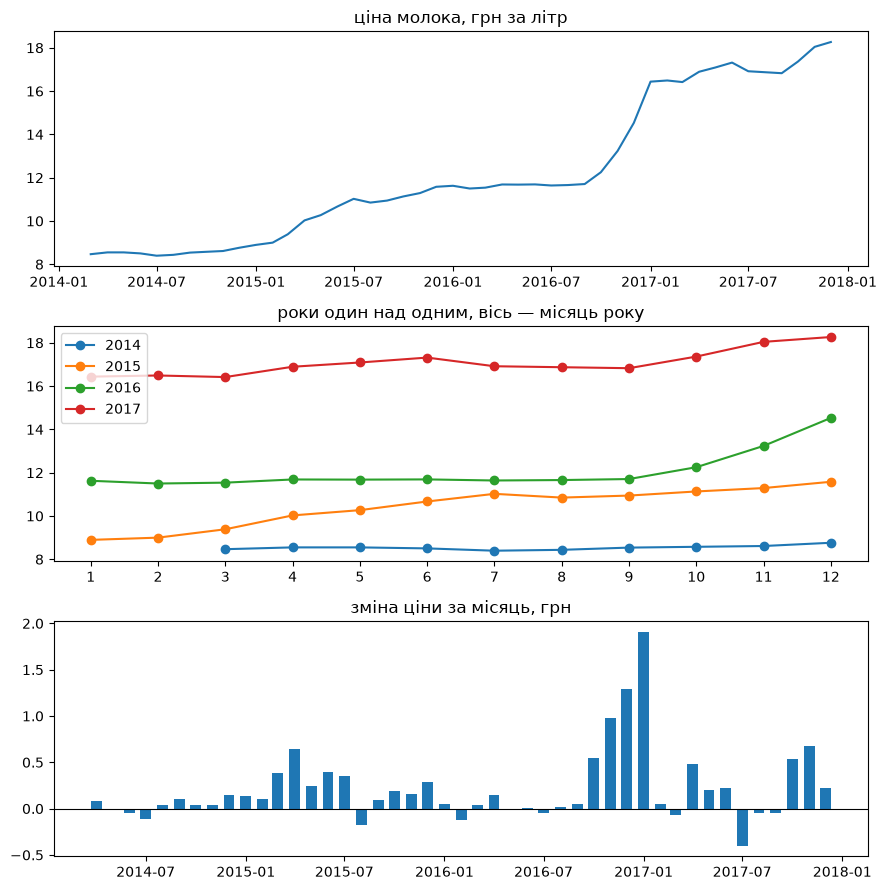

найбільший приріст: 01.2017 1.9067 | 12.2016 + 01.2017: 3.2 з 9.8


In [5]:
growth = s.diff()

fig, ax = plt.subplots(3, 1, figsize=(9, 9))
ax[0].plot(s.index, s.values)
ax[0].set_title('ціна молока, грн за літр')
for year, part in s.groupby(s.index.year):
    ax[1].plot(part.index.month, part.values, marker='o', label=year)
ax[1].set_xticks(range(1, 13))
ax[1].legend()
ax[1].set_title('роки один над одним, вісь — місяць року')
ax[2].bar(growth.index, growth.values, width=20)
ax[2].axhline(0, color='black', lw=0.8)
ax[2].set_title('зміна ціни за місяць, грн')
plt.tight_layout()
plt.show()

print('найбільший приріст:', growth.idxmax().strftime('%m.%Y'), round(growth.max(), 4), '| 12.2016 + 01.2017:', round(growth.loc['2016-12':'2017-01'].sum(), 4), 'з', round(s.iloc[-1] - s.iloc[0], 4))

**Висновок до завдання 3:**

Перший графік — лінія в лінійній шкалі, бо питання в тому, як змінювався рівень ціни, а сусідні місяці пов'язані між собою, і лінія це передає; ціна зросла з 8.47 до 18.27 грн. Другий — роки, накладені один на одного з віссю «місяць року», бо так однакові місяці різних років стоять один над одним і видно, чи повторюється форма року; вона не повторюється — 2014 майже плоский, а 2016 стоїть до осені й стрибає в кінці, тому на око сезонності немає. Третій — стовпчики місячних приростів із нулем на осі, бо приріст — це окрема величина за місяць, а не траєкторія, і без нуля знак зміни читався б неправильно.

Неочікуваним для мене стало те, що зростання дуже нерівномірне: лише два місяці, грудень 2016 і січень 2017, дали 3.2 грн із 9.8 грн усього зростання за чотири роки, тобто третину, а найбільший місячний приріст 1.9067 грн припав на січень 2017.

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

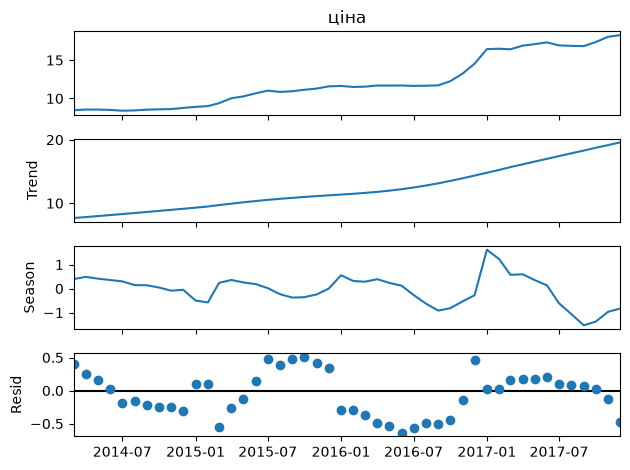

F_S = 0.7846, F_T = 0.9908
сезонна складова січня по роках: [-0.499, 0.553, 1.618]


In [6]:
stl = STL(s, period=12).fit()
stl.plot()
plt.show()

F_S = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
F_T = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
print(f'F_S = {F_S:.4f}, F_T = {F_T:.4f}')
print('сезонна складова січня по роках:', stl.seasonal[stl.seasonal.index.month == 1].round(3).tolist())

**Висновок до завдання 4:**

Формально сезонність є, бо F_S = 0.7846 вище порогу 0.3, але вона нестійка й для прогнозу непридатна, а домінує тренд із F_T = 0.9908. Сезонна складова січня по роках дорівнює −0.499, 0.553 і 1.618, тобто міняє знак і просто всотує стрибок січня 2017, а стала сезонність так не виглядає; до того ж у ряді лише 46 місяців, менше чотирьох повних циклів, і сезонний наївний прогноз у завданні 6 виявився вчетверо гіршим за звичайний наївний. Тому STL сезонну складову виділив, але практичної сезонності в ряді немає.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

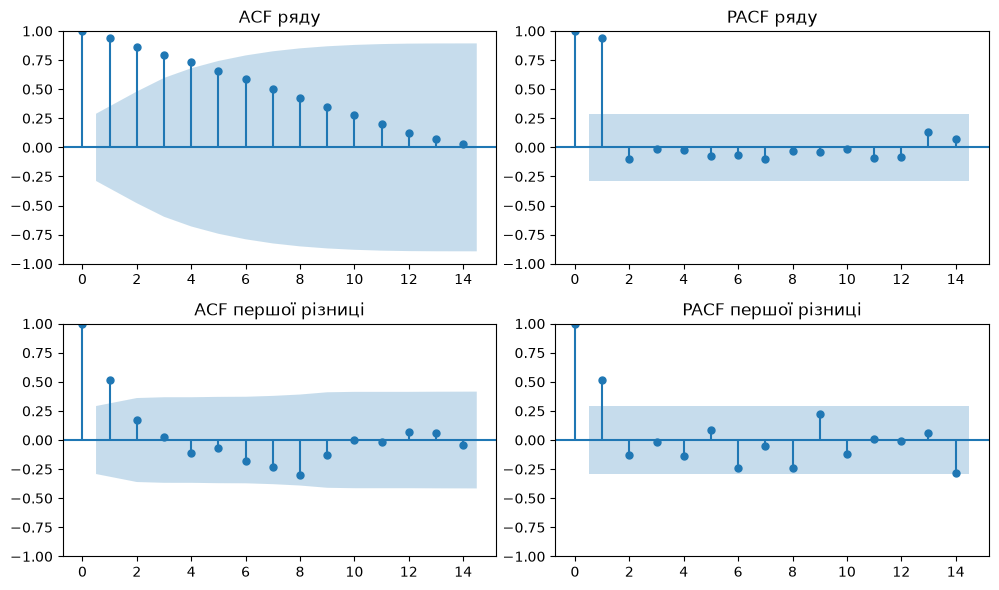

,ADF p,KPSS p
ряд,0.9594,0.01
перша різниця,0.0043,0.10


In [7]:
d1 = s.diff().dropna()

fig, ax = plt.subplots(2, 2, figsize=(10, 6))
plot_acf(s, lags=14, ax=ax[0, 0], title='ACF ряду')
plot_pacf(s, lags=14, ax=ax[0, 1], title='PACF ряду')
plot_acf(d1, lags=14, ax=ax[1, 0], title='ACF першої різниці')
plot_pacf(d1, lags=14, ax=ax[1, 1], title='PACF першої різниці')
plt.tight_layout()
plt.show()

pd.DataFrame({'ADF p': [adfuller(x)[1] for x in (s, d1)], 'KPSS p': [kpss(x)[1] for x in (s, d1)]}, index=['ряд', 'перша різниця']).round(4)

**Висновок до завдання 5:**

Сам ряд нестаціонарний, а його перша різниця стаціонарна, і обидва тести тут узгоджуються. Для рівня ADF дає p = 0.9594, тобто його нульову гіпотезу про нестаціонарність не відхиляємо, а KPSS дає p = 0.01, тобто відхиляємо його нульову гіпотезу про стаціонарність, — обидва кажуть «нестаціонарний»; для першої різниці ADF p = 0.0043 і KPSS p = 0.10, обидва кажуть «стаціонарна» (0.10 — верхня межа таблиці KPSS, справжнє p ще більше).

Графіки показують те саме: ACF рівня спадає повільно й лишається значущою до дев'ятого лагу, як і буває в ряді з трендом, а після диференціювання значущим лишається в основному лаг 1 і в ACF, і в PACF, піку на лагу 12 немає, тому досить одного диференціювання, d = 1.

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [8]:
y = s.values


def backtest(forecast, data):
    errors = []
    for f in range(7, 0, -1):
        train, test = data[:-3 * f], data[-3 * f:][:3]
        e = test - forecast(train, 3)
        errors.append([np.mean(np.abs(e)), np.sqrt(np.mean(e ** 2)), 100 * np.mean(np.abs(e / test))])
    return np.mean(errors, axis=0)


baselines = {
    'наївний': lambda t, h: np.repeat(t[-1], h),
    'сезонний наївний': lambda t, h: t[-12:][:h],
    'середнє': lambda t, h: np.repeat(t.mean(), h),
    'дрейф': lambda t, h: t[-1] + (t[-1] - t[0]) / (len(t) - 1) * np.arange(1, h + 1),
}
table = pd.DataFrame({name: backtest(f, y) for name, f in baselines.items()}, index=['MAE', 'RMSE', 'MAPE %']).T
print(table.round(4))

rng = np.random.default_rng(42)
idx = rng.choice(np.arange(1, len(y)), size=12, replace=False)
random_mae = np.mean(np.abs(y[idx] - y[idx - 1]))
print('наївний на випадковому поділі 75/25: MAE', round(random_mae, 4), '| менше за рухомий початок у', round(table.loc['наївний', 'MAE'] / random_mae, 2), 'раза')

                     MAE    RMSE   MAPE %
наївний           0.8459  0.8946   5.3612
сезонний наївний  3.4514  3.4809  21.4835
середнє           4.3527  4.3740  27.5517
дрейф             0.7367  0.7861   4.7687
наївний на випадковому поділі 75/25: MAE 0.3322 | менше за рухомий початок у 2.55 раза


**Висновок до завдання 6:**

Найкращий базис — дрейф: MAE 0.7367, RMSE 0.7861, MAPE 4.77 %, трохи краще за наївний із MAE 0.8459. Ряд майже весь час росте, і дрейф продовжує середній нахил, тоді як наївний повторює останнє значення й на зростаючому ряді завжди відстає; сезонний наївний (3.4514) і середнє (4.3527) провалюються, бо перший бере ціну річної давнини, а друге — середнє за всі роки, коли ціна вже значно вища.

Випадковий поділ 75/25 дає для наївного прогнозу MAE 0.3322, тобто занижує помилку у 2.55 раза. Після перемішування кожен тестовий місяць прогнозується з відомого сусіднього місяця, а в навчальній частині лежать і пізніші місяці, тож для часового ряду це протікання майбутнього, і оцінка виходить занадто оптимістичною.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

                     MAE    RMSE   MAPE %
наївний           0.8459  0.8946   5.3612
сезонний наївний  3.4514  3.4809  21.4835
середнє           4.3527  4.3740  27.5517
дрейф             0.7367  0.7861   4.7687
ARIMA(1,1,1)      0.7064  0.7692   4.4960
AIC (1,1,0), (0,1,1), (1,1,1): [37.71, 40.488, 39.567] | p коефіцієнтів ar.L1, ma.L1: [0.058 0.831]


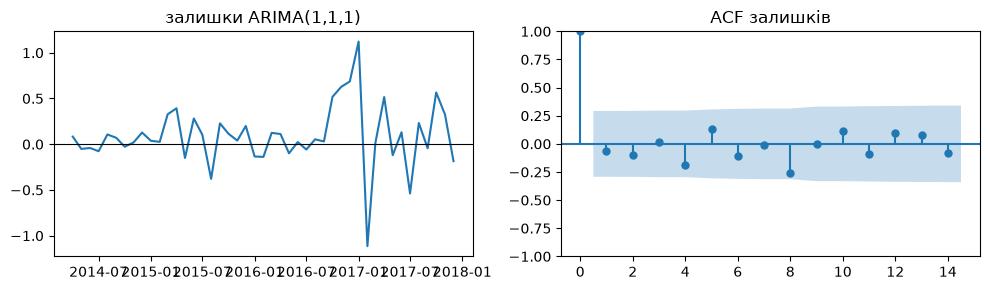

Ljung-Box p на 6 і 12 лагах: [0.6719, 0.6485]


In [9]:
arima = lambda t, h: ARIMA(t, order=(1, 1, 1)).fit().forecast(h)
table.loc['ARIMA(1,1,1)'] = backtest(arima, y)
print(table.round(4))

model = ARIMA(y, order=(1, 1, 1)).fit()
print('AIC (1,1,0), (0,1,1), (1,1,1):', [round(float(ARIMA(y, order=o).fit().aic), 3) for o in [(1, 1, 0), (0, 1, 1), (1, 1, 1)]], '| p коефіцієнтів ar.L1, ma.L1:', model.pvalues[:2].round(3))

resid = model.resid[1:]
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(s.index[1:], resid)
ax[0].axhline(0, color='black', lw=0.8)
ax[0].set_title('залишки ARIMA(1,1,1)')
plot_acf(resid, lags=14, ax=ax[1], title='ACF залишків')
plt.tight_layout()
plt.show()
print('Ljung-Box p на 6 і 12 лагах:', acorr_ljungbox(resid, lags=[6, 12])['lb_pvalue'].round(4).tolist())

**Висновок до завдання 7:**

ARIMA(1,1,1) на тих самих 7 фолдах дала MAE 0.7064, RMSE 0.7692, MAPE 4.50 %, тобто обійшла найкращий базис, дрейф, лише на 0.03 грн, близько 4 %, тому право на існування модель має, але виграш мізерний. Сам я обрав би (1,1,0): на першій різниці PACF має один значущий пік на лагу 1 і далі обривається, а ACF спадає поступово, що відповідає AR(1); це підтверджує й AIC — 37.71 у (1,1,0) проти 39.567 у (1,1,1) і 40.488 у (0,1,1), — а коефіцієнт ma.L1 у заданій моделі незначущий (p = 0.831).

Структури в залишках не лишилось: жоден лаг ACF залишків не виходить за межі, а тест Люнга-Бокса дає p = 0.6719 на шести лагах і 0.6485 на дванадцяти, тобто залишки схожі на шум.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

точка 01.2017 | t = 20.382 | p = 5.406e-24 | перевірок 35
середнє до 10.4476 | після 17.0777
приріст у січні по роках: [0.1334, 0.0467, 1.9067]


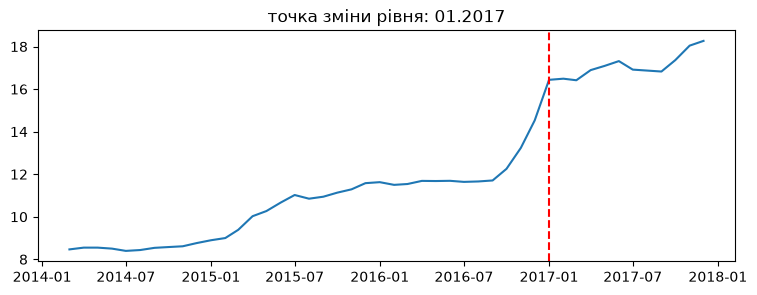

In [10]:
scan = pd.DataFrame([stats.ttest_ind(y[k:], y[:k], equal_var=False) for k in range(6, len(y) - 5)],
                    index=s.index[6:len(y) - 5], columns=['t', 'p'])
k = scan['t'].abs().idxmax()
print('точка', k.strftime('%m.%Y'), '| t =', round(scan.loc[k, 't'], 4), '| p =', f"{scan.loc[k, 'p']:.3e}", '| перевірок', len(scan))
print('середнє до', round(s[s.index < k].mean(), 4), '| після', round(s[s.index >= k].mean(), 4))
print('приріст у січні по роках:', growth[growth.index.month == 1].round(4).tolist())

plt.figure(figsize=(9, 3))
plt.plot(s.index, s.values)
plt.axvline(k, color='red', ls='--')
plt.title(f'точка зміни рівня: {k:%m.%Y}')
plt.show()

**Висновок до завдання 8:**

Точка зміни рівня — січень 2017: t = 20.382, p = 5.4·10⁻²⁴, середній рівень до неї 10.45 грн, після 17.08 грн. Вона значуща навіть з поправкою Бонферроні на 35 перевірок (поріг 0.05 / 35 ≈ 0.0014), хоча саме велике t тут не доказ, бо на ряді з трендом цей тест знайде «зсув» майже будь-де посередині; переконує інше — у січні 2017 ціна за один місяць зросла на 1.9067 грн, і після цього рівень уже не повернувся.

Від сезонного сплеску ця точка відрізняється тим, що не повторюється: у січні 2015 і 2016 прирости були лише 0.1334 і 0.0467 грн, а сезонний пік щороку приходив би в той самий місяць і потім спадав би назад.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [11]:
peer = df[(df['ринок'] == 'Vinnytsia') & (df['товар'] == 'Buckwheat grits - Retail')].set_index('date')['ціна']
print('у колеги точок:', len(peer), '| на повній сітці:', len(peer.reindex(grid)))
peer = peer.reindex(grid).interpolate().values
print('ADF p ряду:', round(adfuller(peer)[1], 4), '| KPSS p ряду:', round(kpss(peer)[1], 4), '| ADF p першої різниці:', round(adfuller(np.diff(peer))[1], 4))
print('рухомий початок на ряді колеги, MAE: наївний', round(backtest(baselines['наївний'], peer)[0], 4), '| ARIMA(1,1,1)', round(backtest(arima, peer)[0], 4))

у колеги точок: 45 | на повній сітці: 46
ADF p ряду: 0.3482 | KPSS p ряду: 0.0182 | ADF p першої різниці: 0.0399
рухомий початок на ряді колеги, MAE: наївний 2.5507 | ARIMA(1,1,1) 2.7741


**Висновок до завдання 9:**

Нумерація клітинок нижче — за порядком у файлі колеги, рахуючи з нуля (клітинка 1 — перша кодова).

| Клітинка | Помилка | Чим небезпечна |
|---|---|---|
| 1 | ряд прочитано без повної місячної сітки, 45 точок замість 46 | серпень 2017 зникає непомітно, усі лаги й різниці після нього зсунуті на місяць |
| 3 | «пропусків немає, обробка не потрібна» | `isna()` на ряді без сітки завжди дає нуль, перевірка нічого не перевіряє |
| 5 | з номінального подорожчання у 2.47 раза зроблено висновок про купівельну спроможність | без інфляції й доходів такий висновок із ціни не випливає |
| 7 | MAE у гривнях порівнюється між гречкою і яловичиною, і це навіть не прогноз, а середня перша різниця по всьому ряду | яловичина в рази дорожча, тому у відсотках рівня її помилка менша — висновок перевернутий, а перевірки прогнозу взагалі немає |
| 9 | з кореляції рівнів r = 0.996 зроблено висновок, що Львів «визначає» Вінницю | кореляція двох трендових рядів завищена спільним трендом, а напрямку причинності вона не показує |
| 11 | «STL виділив сезонну складову, отже ряд сезонний» | STL виділяє її завжди, навіть із шуму; сили сезонності не пораховано |
| 13 | при ADF p = 0.233 написано «ряд стаціонарний» | напрямок переплутано: велике p означає, що нестаціонарність не відхилено |
| 13 | ряд продиференційовано двічі «для надійності» | це перебір, ACF(1) другої різниці −0.13; першої різниці достатньо |
| 15 | у тексті поріг «два стандартні відхилення», у коді 1.3, і аномалії шукають у ряді з трендом | «аномаліями» стали всі місяці 2014 і літо 2016, тобто низ і верх тренду; шукати треба в залишках |
| 17 | `train_test_split` із перемішуванням, прогноз порівнюється з `np.sort(y_te)` | майбутнє потрапляє в навчання, прогноз зіставлено не з тими датами, тому 8.73 грн нічого не означає |
| 17 | сезонний наївний пораховано по всьому ряду, а ARIMA — на тесті | метрики на різних вибірках незіставні, а помилка 8.73 грн при ціні 7–18 грн аж ніяк не «висока точність» |
| 19 | порядок без пояснення змінено на (2,2,1), прогноз 8.95 грн при останньому факті 17.67, а висновок «ціна зростатиме» | висновок суперечить власному числу моделі |
| 21 | стовпчики з віссю, що починається не з нуля | невелика зміна виглядає як «стрімке зростання» |
| 22 | у загальних висновках ряд водночас «зріс у кілька разів» і «стаціонарний» | зростаючий ряд не може бути стаціонарним, висновки суперечать один одному |

Найсерйозніші три. Перша — випадковий поділ у клітинці 17, бо через нього головне число звіту не має сенсу; виправлення — ретроспективна перевірка з рухомим початком, і на ряді колеги 7 фолдів по 3 кроки дають MAE 2.5507 для наївного прогнозу й 2.7741 для ARIMA(1,1,1), тобто модель програє найпростішому базису і висновок звіту стає протилежним. Друга — напрямок ADF у клітинці 13: ADF треба читати як «мале p означає стаціонарність» і ставити в пару з KPSS, і тоді рівень нестаціонарний (ADF p = 0.3482, KPSS p = 0.0182), перша різниця стаціонарна (ADF p = 0.0399), d = 1. Третя — відсутність сітки в клітинці 1: треба одразу зробити `reindex` на повну сітку, побачити пропуск у серпні 2017 і заповнити його, і лише тоді рахувати все інше.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [12]:
pd.DataFrame({'date': s.index.strftime('%Y-%m-%d'), 'price': s.values.round(4)}).to_csv('ряд_для_orange.csv', index=False)
check = pd.read_csv('ряд_для_orange.csv')
print('рядків даних:', len(check), '| порожніх значень:', check.isna().sum().sum())
check.head(3)

рядків даних: 46 | порожніх значень: 0


,date,price
0,2014-03-01,8.4667
1,2014-04-01,8.5500
2,2014-05-01,8.5500


**Висновок до завдання 10:**

Файл `ряд_для_orange.csv` має 46 рядків даних і заголовок, порожніх значень немає, дата записана у форматі РРРР-ММ-ДД (2014-03-01), який Orange розпізнає як time, а ціна — числом із чотирма знаками, як у вихідному наборі.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

In [13]:
print('точок', len(s), '| перше', s.iloc[0], '| останнє', s.iloc[-1], '| мінімум', s.min(), s.idxmin().strftime('%m.%Y'))

точок 46 | перше 8.4667 | останнє 18.2667 | мінімум 8.3967 07.2014


**Висновок до завдання 11:**

![Потік у Orange](orange1.png)

![Line Chart](orange2.png)

У Orange я зібрав потік File → Form Timeseries → Interpolate → Line Chart (у цій версії Orange віджет As Timeseries називається Form Timeseries). У File завантажив `ряд_для_orange.csv` із завдання 10: `date` розпізнано як time, `price` як numeric, і `price` я позначив цільовою змінною (target), щоб із нею далі працювала модель. В Interpolate стоїть лінійна інтерполяція, як і в Python. Line Chart показує той самий графік, що й перший графік завдання 3: 46 точок, від 8.47 до 18.27 грн і різкий стрибок на початку 2017 року, тобто Orange отримав ті самі дані.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

In [14]:
print('ACF ряду, лаги 1–9:', acf(s, nlags=9)[1:].round(3))
print('ACF першої різниці, лаги 1 і 8:', acf(d1, nlags=8)[[1, 8]].round(3))
for name, x in (('ряд', s), ('перша різниця', s.diff().bfill())):
    r = acf(x, nlags=int(0.9 * len(x)))
    peaks = argrelextrema(np.abs(r), np.greater, order=3)[0]
    band = 1.96 * np.sqrt((1 + 2 * np.sum(r[peaks] ** 2)) / len(x))
    print(name, '| лаги, які малює Correlogram:', dict(zip(peaks.tolist(), r[peaks].round(3).tolist())), '| смуга ±', round(band, 3))
classic = seasonal_decompose(s, period=12)
print('розмах сезонної складової: STL', round(stl.seasonal.max() - stl.seasonal.min(), 4), '| класичне розкладання, як у Seasonal Adjustment', round(classic.seasonal.max() - classic.seasonal.min(), 4))

ACF ряду, лаги 1–9: [0.938 0.867 0.798 0.731 0.66  0.586 0.505 0.426 0.35 ]
ACF першої різниці, лаги 1 і 8: [ 0.513 -0.301]
ряд | лаги, які малює Correlogram: {33: -0.443} | смуга ± 0.341
перша різниця | лаги, які малює Correlogram: {8: -0.296, 19: 0.157, 27: -0.135, 38: 0.025} | смуга ± 0.325
розмах сезонної складової: STL 3.147 | класичне розкладання, як у Seasonal Adjustment 0.9808


**Висновок до завдання 12:**

![Correlogram](orange3.png)

![Seasonal Adjustment](orange4.png)

Я додав Difference (перша різниця ряду), Correlogram і Seasonal Adjustment. Значення автокореляції в Orange ті самі, що й у Python (наприклад, лаг 8 у різниці дає −0.296 в Orange і −0.301 у Python), але Orange малює не всі лаги, а лише ті, що виділяються серед сусідніх. Тому для ряду видно тільки лаг 33, а для різниці — лаги 8, 19, 27 і 38, і жоден із них не виходить за межу значущості; висновок про тренд і про одне диференціювання я роблю за ACF із завдання 5, де видно всі лаги. Seasonal Adjustment розкладає ряд класичним способом, і сезонна складова в нього маленька — розмах 0.98 грн проти 3.15 грн у STL, тож скоригований ряд майже не відрізняється від вихідного, і це підтверджує висновок завдання 4: сезонність слабка.

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

In [15]:
for f in range(1, 8):
    print(f'fold {f}: навчання 03.2014–{s.index[-3 * f - 1]:%m.%Y} (точок: {len(y) - 3 * f}), прогноз {s.index[-3 * f]:%m.%Y}–{s.index[len(y) - 3 * f + 2]:%m.%Y}')
print('20 фолдів × 3 кроки + лаг 1 =', 20 * 3 + 1, '> довжина ряду', len(y))

fold 1: навчання 03.2014–09.2017 (точок: 43), прогноз 10.2017–12.2017
fold 2: навчання 03.2014–06.2017 (точок: 40), прогноз 07.2017–09.2017
fold 3: навчання 03.2014–03.2017 (точок: 37), прогноз 04.2017–06.2017
fold 4: навчання 03.2014–12.2016 (точок: 34), прогноз 01.2017–03.2017
fold 5: навчання 03.2014–09.2016 (точок: 31), прогноз 10.2016–12.2016
fold 6: навчання 03.2014–06.2016 (точок: 28), прогноз 07.2016–09.2016
fold 7: навчання 03.2014–03.2016 (точок: 25), прогноз 04.2016–06.2016
20 фолдів × 3 кроки + лаг 1 = 61 > довжина ряду 46


**Висновок до завдання 13:**

![Model Evaluation](orange5.png)

![Помилка при 20 фолдах](orange6.png)

Я додав ARIMA Model з порядком (1,1,1) і Model Evaluation. З налаштуваннями за замовчуванням (20 фолдів по 3 кроки) Orange не рахує й пише, що ряд закороткий: для 20 фолдів треба 20 · 3 + 1 = 61 місяць, а в моєму ряді їх 46, тож найбільше можна взяти 15 фолдів. З 7 фолдами по 3 кроки Orange дає RMSE 0.956, MAE 0.564, MAPE 0.047 і POCID 50.

Фолди Orange рахує від кінця ряду: перший навчається на 43 місяцях і прогнозує жовтень–грудень 2017, сьомий — на 25 місяцях і прогнозує квітень–червень 2016. Отже перевіряються ті самі останні 21 місяць, що й у Python. Другий рядок таблиці («in-sample») — це модель, навчена на всіх 46 місяцях без перевірки на майбутньому, тому для порівняння з Python я беру перший рядок.

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [16]:
true, pred = [], []
for f in range(1, 8):
    true.extend(y[-3 * f:][:3])
    pred.extend(arima(y[:-3 * f], 3))
true, pred = np.array(true), np.array(pred)
e = true - pred

pd.DataFrame({
    'як рахує Orange': [np.sqrt(np.mean(e ** 2)), np.median(np.abs(e)), np.mean(np.abs(e)) / np.mean(np.abs(true)), 100 * np.mean(np.diff(true) * np.diff(pred) > 0)],
    'звичайне означення': [np.sqrt(np.mean(e ** 2)), np.mean(np.abs(e)), 100 * np.mean(np.abs(e / true)), np.nan],
    'формула Orange': ['sqrt(sum(e^2) / n)', 'median(|e|)', 'mean(|e|) / mean(|y|)', '100 * частка збігу напрямку'],
}, index=['RMSE', 'MAE', 'MAPE', 'POCID']).round(6)

,як рахує Orange,звичайне означення,формула Orange
RMSE,0.955680,0.955680,sqrt(sum(e^2) / n)
MAE,0.564244,0.706428,median(|e|)
MAPE,0.047093,4.495992,mean(|e|) / mean(|y|)
POCID,50.000000,NaN,100 * частка збігу напрямку


**Висновок до завдання 14:**

| Метрика | Orange | Python | Формула Orange |
|---|---|---|---|
| RMSE | 0.956 | 0.955680 | `sqrt(sum(e²) / n)` |
| MAE | 0.564 | 0.564244 | `median(|e|)` |
| MAPE | 0.047 | 0.047093 | `mean(|e|) / mean(|y|)` |
| POCID | 50.0 | 50.000000 | `100 · частка пар зі збігом знака зміни` |

Усі чотири числа Orange я отримав і в Python, отже модель в обох програмах прогнозує однаково, а різниця з Частиною 1 виникає тільки через те, як Orange рахує метрики. Своїй назві не відповідає MAE: зазвичай це середня абсолютна похибка (у мене 0.706), а Orange бере медіану (0.564). MAPE в Orange теж рахується інакше — середня похибка ділиться на середню ціну, і результат подано часткою 0.047, а не відсотками (звичайна MAPE 4.50 %). POCID показує не розмір помилки, а як часто модель вгадує напрямок зміни ціни.

RMSE рахується однаково, тому вона збіглася відразу, щойно я порахував її так само, як Orange, — на всіх 21 прогнозі разом (0.956); у Частині 1 я усереднював її по фолдах і отримав 0.769. Тому перед порівнянням чисел із двох програм треба перевірити, що в них однакові дані, модель, фолди й формули метрик.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [17]:
went_up, said_up = np.diff(true) > 0, np.diff(pred) > 0
print(pd.crosstab(np.where(went_up, 'зросла', 'впала'), np.where(said_up, 'зросте', 'впаде'), rownames=['насправді'], colnames=['модель']))
print('частка правильних напрямків:', np.mean(went_up == said_up))

модель     впаде  зросте
насправді               
впала          4       5
зросла         5       6
частка правильних напрямків: 0.5


**Висновок до завдання 15:**

Модель правильно вгадала напрямок зміни ціни в 10 випадках із 20: 6 разів зростання і 4 рази падіння. Частка 0.5 збігається з POCID = 50 в Orange. Для рішення «купувати зараз чи чекати» така модель не допомагає, бо напрямок вона вгадує як підкинута монетка. При цьому за розміром помилки вона непогана (MAPE 4.5 %): MAE і RMSE показують, наскільки прогноз близький до ціни, а для зростаючого ряду це нескладно — досить продовжувати тренд, навіть не вгадуючи, чи ціна наступного місяця трохи вища чи трохи нижча.

---
# Загальний висновок

Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?

Сезонність у ряді формально є (F_S = 0.7846 при порозі 0.3), але вона нестійка: січень щороку різний, класичне розкладання дає зовсім малу сезонну складову, а сезонний наївний прогноз учетверо гірший за звичайний, тому ряд фактично визначає тренд. Найкращим базисом став дрейф (MAE 0.7367), а ARIMA(1,1,1) обійшла його лише на 3 копійки (MAE 0.7064); за графіками ACF і PACF я обрав би простішу модель (1,1,0). Точка зміни рівня — січень 2017 року: середня ціна піднялася з 10.45 до 17.08 грн і вже не повернулася. За часом це збігається з подвоєнням мінімальної зарплати з 1 січня 2017 року, але з одного ряду довести причину не можна.

Той самий аналіз я повторив в Orange, і модель там прогнозує так само, як у Python. Однаково названі метрики дали різні числа лише тому, що Orange рахує їх по-іншому: MAE як медіану, MAPE як частку з іншою формулою, а всі метрики — одразу на всіх прогнозах, а не по фолдах; кожне число Orange я відтворив у Python. Через те що в ряді лише 46 місяців, я не можу надійно оцінити сезонність (це менше чотирьох років), перевірити складніші моделі й переконатися, що точка зміни стійка, бо після неї лишається тільки 12 місяців.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Claude Code (Anthropic), модель Claude Opus 5 |
| Для яких саме завдань | код і чернетки висновків до завдань 1–10, 14 і 15; в Orange (завдання 11–13) працював сам |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | код і чернетки висновків |
| Що ви змінили у згенерованому результаті й чому | скоротив код і спростив висновки, щоб вони відповідали саме на питання завдань |
| Що з отриманого ви **перевірили самостійно** і яким способом | звірив усі числа у висновках із виводом зошита; метрики Orange порівняв із розрахунком у Python |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | траплялися дрібні помилки в коді, які я помітив під час запуску й виправив |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: ______________________  Дата: ______________